In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
file_path = ("/kaggle/input/datasets/mudasir123312/school-attendance/2018-2019_Daily_Attendance_20240429.csv")
df = pd.read_csv(file_path)
df.head()

,School DBN,Date,Enrolled,Absent,Present,Released
0,01M015,20180905,172,19,153,0
1,01M015,20180906,171,17,154,0
2,01M015,20180907,172,14,158,0
3,01M015,20180912,173,7,166,0
4,01M015,20180913,173,9,164,0


In [6]:
X = df[['Enrolled']].values
y = df['Present'].values

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
degree = 2
poly = PolynomialFeatures(degree=degree)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)

LinearRegression()

In [9]:
y_pred = model.predict(X_test_poly)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R2 Score: {r2:.4f}")

Mean Squared Error: 3475.02
R2 Score: 0.9826


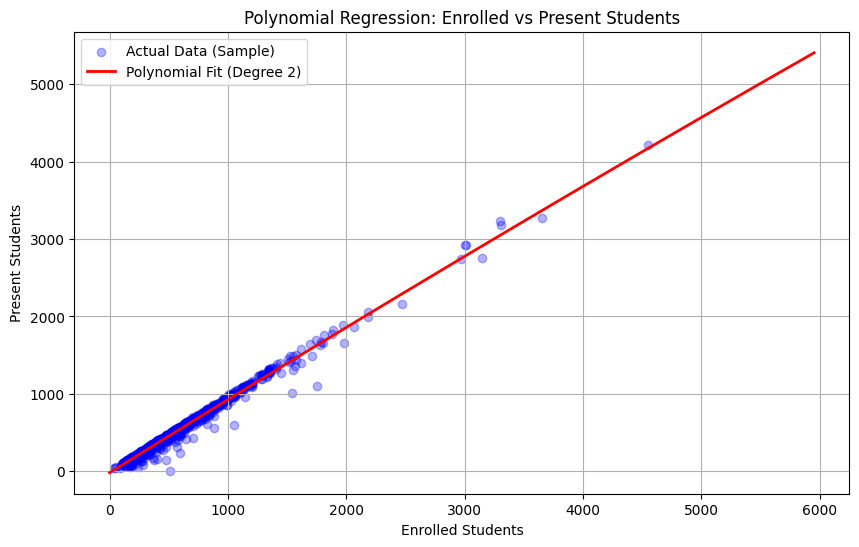

In [10]:
plt.figure(figsize=(10, 6))

indices = np.random.choice(len(X_test), size=1000, replace=False)
plt.scatter(X_test[indices], y_test[indices], color='blue', alpha=0.3, label='Actual Data (Sample)')

X_range = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
X_range_poly = poly.transform(X_range)
y_range_pred = model.predict(X_range_poly)

plt.plot(X_range, y_range_pred, color='red', linewidth=2, label=f'Polynomial Fit (Degree {degree})')

plt.title('Polynomial Regression: Enrolled vs Present Students')
plt.xlabel('Enrolled Students')
plt.ylabel('Present Students')
plt.legend()
plt.grid(True)
plt.show()